In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt


# Zmiana pojedynczego typu pliku

In [5]:
from PIL import Image

obraz = str("test-images/00085_931230_pl.ppm")

# Wczytaj plik PPM
img = Image.open(obraz)

# Zapisz jako PNG
img.save(obraz + ".png")  # Dodaj rozszerzenie .png

# Zmiana serii plików w folderze

In [6]:
import rawpy
import imageio.v3 as iio
import os

raw_dir = "test-images"
raw_exts = ['.dng', '.nef', '.cr2', '.arw', '.raw', '.rw2', '.orf', '.pef']

for fname in os.listdir(raw_dir):
    ext = os.path.splitext(fname)[1].lower()
    if ext in raw_exts:
        raw_path = os.path.join(raw_dir, fname)
        try:
            with rawpy.imread(raw_path) as raw:
                rgb = raw.postprocess()
            # Zapisz jako PNG
            out_png = raw_path + ".png"
            iio.imwrite(out_png, rgb)
            print(f"Zapisano {out_png}")
            # Zapisz jako JPEG
            out_jpg = raw_path + ".jpeg"
            iio.imwrite(out_jpg, rgb)
            print(f"Zapisano {out_jpg}")
            # Zapisz jako JPG
            out_jpg = raw_path + ".jpg"
            iio.imwrite(out_jpg, rgb)
            print(f"Zapisano {out_jpg}")
            # Zapisz jako PPM
            out_ppm = raw_path + ".ppm"
            iio.imwrite(out_ppm, rgb)
            print(f"Zapisano {out_ppm}")
        except Exception as e:
            print(f"Błąd konwersji {raw_path}: {e}")


Zapisano test-images\moje (1).dng.png
Zapisano test-images\moje (1).dng.jpeg
Zapisano test-images\moje (1).dng.jpg
Zapisano test-images\moje (1).dng.ppm
Zapisano test-images\moje (2).dng.png
Zapisano test-images\moje (2).dng.jpeg
Zapisano test-images\moje (2).dng.jpg
Zapisano test-images\moje (2).dng.ppm
Zapisano test-images\moje (3).dng.png
Zapisano test-images\moje (3).dng.jpeg
Zapisano test-images\moje (3).dng.jpg
Zapisano test-images\moje (3).dng.ppm
Zapisano test-images\moje (4).dng.png
Zapisano test-images\moje (4).dng.jpeg
Zapisano test-images\moje (4).dng.jpg
Zapisano test-images\moje (4).dng.ppm
Zapisano test-images\moje (5).dng.png
Zapisano test-images\moje (5).dng.jpeg
Zapisano test-images\moje (5).dng.jpg
Zapisano test-images\moje (5).dng.ppm
Zapisano test-images\moje (6).dng.png
Zapisano test-images\moje (6).dng.jpeg
Zapisano test-images\moje (6).dng.jpg
Zapisano test-images\moje (6).dng.ppm


# Kompresja JPEG i JPEG 2000

In [7]:
from PIL import Image

obraz = str("test-images/00085_931230_pl.ppm")

# Otwórz plik PPM
img = Image.open(obraz)

# Zapisz jako JPEG (klasyczny)
img.save(obraz + ".jpg", "JPEG", quality=85)
img.save(obraz + "-100%.jpg", "JPEG", quality=100)

# Zapisz jako JPEG 2000
img.save(obraz + ".jp2", "JPEG2000", quality_mode='rates', quality_layers=[0.3])

# Wykrywanie blokowości - Laplace

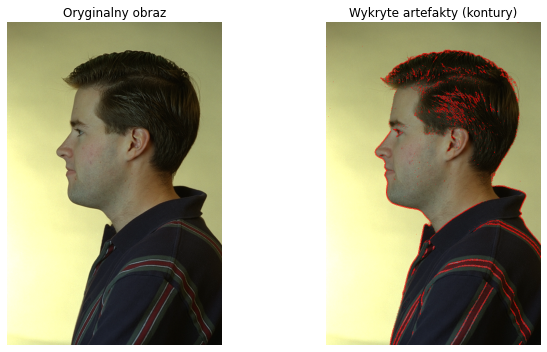

In [2]:
# Wczytanie obrazu
image_path = "test-images/00085_931230_pl.ppm"
img = cv2.imread(image_path)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

# Obraz oryginalny
plt.figure(figsize=(10,5))
plt.subplot(1,2,1)
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Oryginalny obraz")
plt.axis('off')

# Wykrywanie artefaktów (np. blokowości) przy użyciu filtru Laplace’a
laplacian = cv2.Laplacian(gray, cv2.CV_64F)
laplacian_abs = np.uint8(np.absolute(laplacian))

# Wykrywanie konturów miejsc o silnych krawędziach (potencjalne artefakty)
_, thresh = cv2.threshold(laplacian_abs, 50, 255, cv2.THRESH_BINARY)
contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)

# Nałóż kontury na oryginalny obraz
img_marked = img.copy()
cv2.drawContours(img_marked, contours, -1, (0, 0, 255), 1)

# Wynik
plt.subplot(1,2,2)
plt.imshow(cv2.cvtColor(img_marked, cv2.COLOR_BGR2RGB))
plt.title("Wykryte artefakty (kontury)")
plt.axis('off')

plt.tight_layout()
plt.show()

# Definiowanie wskaźników

In [1]:
import os

# Funkcje do wykrywania kompresji JPEG

def detect_jpeg_blockiness(image):
    """Wykrywa blokowość charakterystyczną dla JPEG (bloki 8x8 pikseli)"""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if len(image.shape) > 2 else image
    
    # Obliczanie różnic pomiędzy sąsiednimi pikselami
    h_diff = np.abs(gray[:, 1:] - gray[:, :-1]) #prawy sąsiad
    v_diff = np.abs(gray[1:, :] - gray[:-1, :]) #dolny sąsiad
    
    # Analizujemy wartości różnic na granicach bloków 8x8
    h_block_diff = h_diff[:, 7::8]  # co 8 pikseli w poziomie
    v_block_diff = v_diff[7::8, :]
    
    # Średnia różnica na granicach bloków vs pozostałe różnice
    h_non_block = np.delete(h_diff, np.arange(7, h_diff.shape[1], 8), axis=1)   # usuwamy co 8 kolumnę (od 7-mej)
    v_non_block = np.delete(v_diff, np.arange(7, v_diff.shape[0], 8), axis=0)   # usuwamy co 8 wiersz (od 7-mego)
    
    block_diff_mean = (np.mean(h_block_diff) + np.mean(v_block_diff)) / 2
    non_block_diff_mean = (np.mean(h_non_block) + np.mean(v_non_block)) / 2
    
    # Współczynnik blokowości
    if non_block_diff_mean > 0:
        blockiness_ratio = block_diff_mean / non_block_diff_mean
    else:
        blockiness_ratio = 0
    
    return blockiness_ratio

def detect_jpeg_blockiness_extended(image):
    """Rozszerzona wersja wykrywania blokowości z dodatkową analizą statystyczną"""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if len(image.shape) > 2 else image
    
    # Obliczanie różnic pomiędzy sąsiednimi pikselami
    h_diff = np.abs(gray[:, 1:] - gray[:, :-1]) #prawy sąsiad
    v_diff = np.abs(gray[1:, :] - gray[:-1, :]) #dolny sąsiad
    
    # Analizujemy wartości różnic na granicach bloków 8x8
    h_block_diff = h_diff[:, 7::8]  # co 8 pikseli w poziomie
    v_block_diff = v_diff[7::8, :]
    
    # Średnia różnica na granicach bloków vs pozostałe różnice
    h_non_block = np.delete(h_diff, np.arange(7, h_diff.shape[1], 8), axis=1)   # usuwamy co 8 kolumnę (od 7-mej)
    v_non_block = np.delete(v_diff, np.arange(7, v_diff.shape[0], 8), axis=0)   # usuwamy co 8 wiersz (od 7-mego)
    
    block_diff_mean = (np.mean(h_block_diff) + np.mean(v_block_diff)) / 2
    non_block_diff_mean = (np.mean(h_non_block) + np.mean(v_non_block)) / 2
    
    # Odchylenie standardowe różnic
    block_diff_std = (np.std(h_block_diff) + np.std(v_block_diff)) / 2
    non_block_diff_std = (np.std(h_non_block) + np.std(v_non_block)) / 2
    
    # Współczynnik blokowości
    if non_block_diff_mean > 0:
        blockiness_ratio = block_diff_mean / non_block_diff_mean
    else:
        blockiness_ratio = 0
    
    return blockiness_ratio, block_diff_std, non_block_diff_std

def visualize_blockiness(image):
    """Tworzy mapę cieplną pokazującą granice bloków 8x8"""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if len(image.shape) > 2 else image
    
    # Obliczanie różnic na granicach bloków 8x8
    blockiness_map = np.zeros_like(gray, dtype=float)
    
    # Pionowe granice bloków
    for i in range(7, gray.shape[0], 8):
        if i+1 < gray.shape[0]:
            blockiness_map[i, :] = np.abs(np.float32(gray[i, :]) - np.float32(gray[i+1, :]))
    
    # Poziome granice bloków
    for j in range(7, gray.shape[1], 8):
        if j+1 < gray.shape[1]:
            blockiness_map[:, j] += np.abs(np.float32(gray[:, j]) - np.float32(gray[:, j+1]))
    
    # Normalizacja do zakresu 0-255
    blockiness_map = cv2.normalize(blockiness_map, None, 0, 255, cv2.NORM_MINMAX)
    
    return blockiness_map.astype(np.uint8)

# Niemiarodajna metoda oszacowania jakości JPEG
def estimate_jpeg_quality(image):
    """Szacuje jakość kompresji JPEG poprzez porównanie z rekompresją obrazu
    
    Funkcja ta próbuje określić jakość kompresji JPEG oryginalnego obrazu poprzez:
    1. Rekompresję obrazu z różnymi poziomami jakości (10%, 20%, ..., 100%)
    2. Porównanie każdej rekompresji z oryginałem przy użyciu MSE (Mean Squared Error)
    3. Wybranie poziomu jakości, który daje najbardziej podobny obraz
    
    UWAGA: Ta metoda mooże być niemiarodajna, ponieważ:
    - Nie uwzględnia pierwotnych parametrów kompresji JPEG
    - Nie różnicuje między obrazami nieskompresowanymi a wysoką jakością JPEG
    - Może dawać błędne wyniki dla obrazów z podwójną kompresją
    """

    # Konwersja do skali szarości jeśli obraz jest kolorowy
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if len(image.shape) > 2 else image
    
    quality_scores = []
    qualities = range(10, 101, 10)  # Testowane jakości: 10, 20, 30, ..., 100
    
    for quality in qualities:
        # Zapisz obraz do bufora z określoną jakością JPEG
        encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
        _, encoded_img = cv2.imencode('.jpg', gray, encode_param)
        
        # Odczytaj skompresowany obraz z powrotem
        decoded_img = cv2.imdecode(encoded_img, cv2.IMREAD_GRAYSCALE)
        
        # Oblicz MSE (Mean Squared Error) - średni błąd kwadratowy
        # Im mniejszy MSE, tym bardziej podobne obrazy
        mse = np.mean((gray.astype(np.float32) - decoded_img.astype(np.float32)) ** 2)
        
        # Oblicz PSNR (Peak Signal-to-Noise Ratio) - stosunek sygnału do szumu
        # Im wyższy PSNR (w dB), tym lepsza jakość
        psnr = 10 * np.log10((255 ** 2) / mse) if mse > 0 else float('inf')
        
        quality_scores.append((quality, mse, psnr))
    
    # Sortuj wyniki według MSE (rosnąco) - najmniejszy MSE = najbardziej podobny
    quality_scores.sort(key=lambda x: x[1])
    
    # Pierwszy element to jakość z najmniejszym MSE
    estimated_quality = quality_scores[0][0]
    best_psnr = quality_scores[0][2]
    
    return estimated_quality, best_psnr

def analyze_dct_spectrum(image):
    """Analizuje widmo częstotliwości poprzez DCT (Discrete Cosine Transform) na blokach 8x8"""
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY) if len(image.shape) > 2 else image
    
    # Przekształcamy obraz do wymiaru podzielnego przez 8
    h, w = gray.shape
    h_pad, w_pad = h - (h % 8), w - (w % 8)
    gray = gray[:h_pad, :w_pad]
    
    # Dzielmy obraz na bloki 8x8
    blocks = []
    for i in range(0, h_pad, 8):
        for j in range(0, w_pad, 8):
            blocks.append(gray[i:i+8, j:j+8])
    
    # Obliczamy DCT dla każdego bloku
    dct_energy = []
    for block in blocks:
        dct = cv2.dct(np.float32(block))
        # Energia składowych AC (wszystkie oprócz DC, czyli [0,0])
        ac_energy = np.sum(np.abs(dct)) - np.abs(dct[0,0])
        dct_energy.append(ac_energy)
    
    # Rozkład energii w blokach może wskazywać na kompresję JPEG
    energy_std = np.std(dct_energy)
    energy_mean = np.mean(dct_energy)
    
    return energy_mean, energy_std

# Główna funkcja do wykrywania kompresji JPEG
def detect_jpeg_compression(image_path):
    # Wczytaj obraz
    img = cv2.imread(image_path)
    if img is None:
        return "Nie można wczytać obrazu"
    
    # 1. Wykrywanie blokowości
    blockiness_ratio = detect_jpeg_blockiness(img)
    blockiness_map = visualize_blockiness(img)
    
    # 2. Analiza widma częstotliwości
    energy_mean, energy_std = analyze_dct_spectrum(img)
    
    # 3. Oszacowanie jakości kompresji
    estimated_quality, psnr = estimate_jpeg_quality(img)
    
    # Decyzja o kompresji na podstawie kombinacji wskaźników
    # Typowa wartość współczynnika blokowości dla JPEG wynosi powyżej 1.1
    is_jpeg = blockiness_ratio > 1.1
    
    # Wizualizacja wyników
    plt.figure(figsize=(15, 10))
    
    # Oryginalny obraz
    plt.subplot(2, 2, 1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("Oryginalny obraz")
    plt.axis('off')
    
    # Mapa blokowości
    plt.subplot(2, 2, 2)
    plt.imshow(blockiness_map, cmap='hot')
    plt.title(f"Mapa blokowości (współczynnik: {blockiness_ratio:.2f})")
    plt.axis('off')
    
    # Wizualizacja siatki 8x8
    plt.subplot(2, 2, 3)
    img_grid = img.copy()
    h, w = img.shape[:2]
    # Rysuj pionowe linie
    for i in range(0, w, 8):
        cv2.line(img_grid, (i, 0), (i, h), (0, 255, 0), 1)
    # Rysuj poziome linie
    for j in range(0, h, 8):
        cv2.line(img_grid, (0, j), (w, j), (0, 255, 0), 1)
    plt.imshow(cv2.cvtColor(img_grid, cv2.COLOR_BGR2RGB))
    plt.title("Wizualizacja siatki 8x8 pikseli")
    plt.axis('off')
    
    # Informacje o kompresji
    plt.subplot(2, 2, 4)
    plt.axis('off')
    info_text = f"Wyniki analizy:\n"
    info_text += f"- Wykryto kompresję JPEG: {'TAK' if is_jpeg else 'NIE'}\n"
    info_text += f"- Współczynnik blokowości: {blockiness_ratio:.2f}\n"
    info_text += f"- Średnia energia DCT: {energy_mean:.2f}\n"
    info_text += f"- Odchylenie energii DCT: {energy_std:.2f}\n"
    info_text += f"- Szacowana jakość JPEG: {estimated_quality}%\n"
    info_text += f"- PSNR: {psnr:.2f} dB"
    plt.text(0.1, 0.5, info_text, fontsize=12)
    
    plt.tight_layout()
    plt.show()
    
    return is_jpeg, blockiness_ratio, estimated_quality, psnr


# print(f"Wynik detekcji kompresji JPEG:")
# print(f"- Wykryto kompresję: {'TAK' if is_jpeg else 'NIE'}")
# print(f"- Współczynnik blokowości: {blockiness:.2f}")
# print(f"- Szacowana jakość: {quality}%")
# print(f"- PSNR: {psnr:.2f} dB")

In [10]:
# # Get all files in the test-images directory
# image_files = [os.path.join("test-images", f) for f in os.listdir("test-images") if os.path.isfile(os.path.join("test-images", f))]
# # Process each image file
# for image_path in image_files:
#     print(f"\nAnalyzing: {image_path}")
#     try:
#         is_jpeg, blockiness, quality, psnr = detect_jpeg_compression(image_path)
#     except Exception as e:
#         print(f"Error processing {image_path}: {e}")

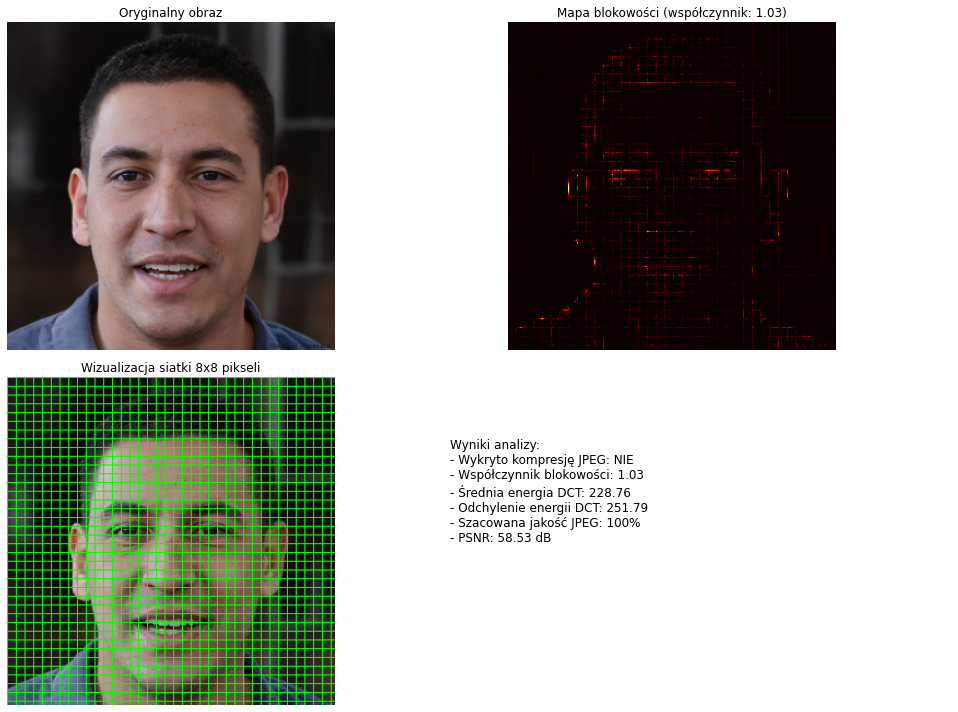

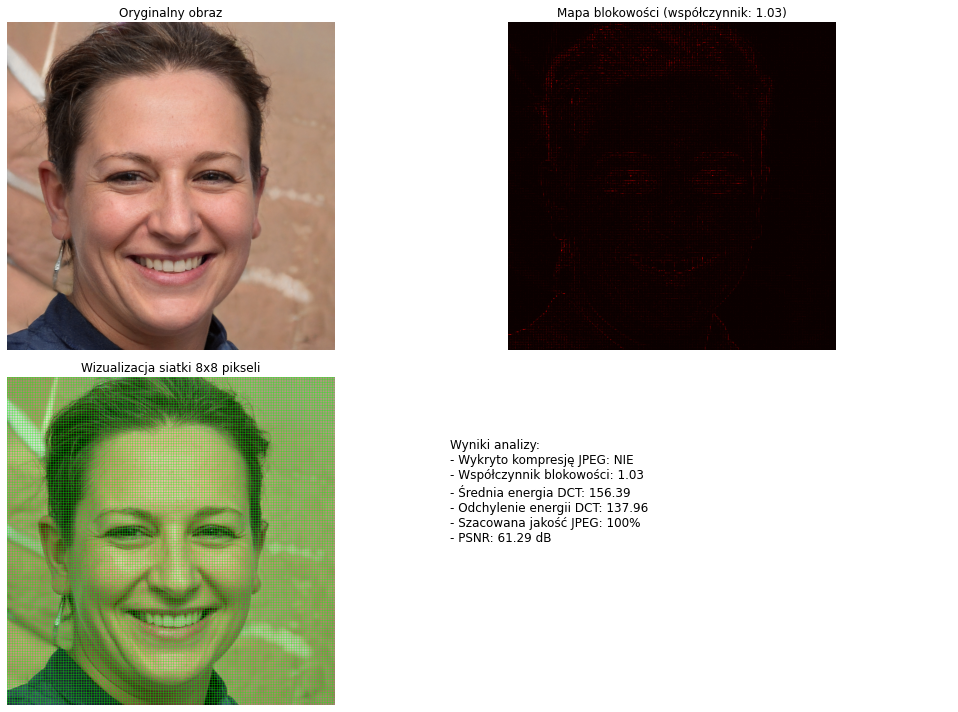

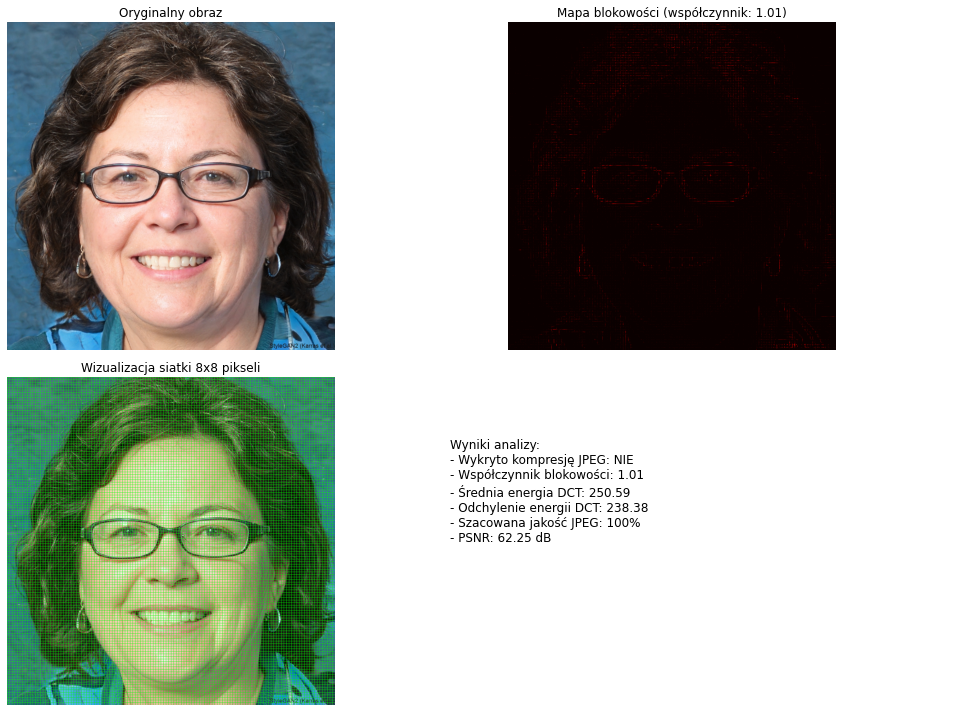

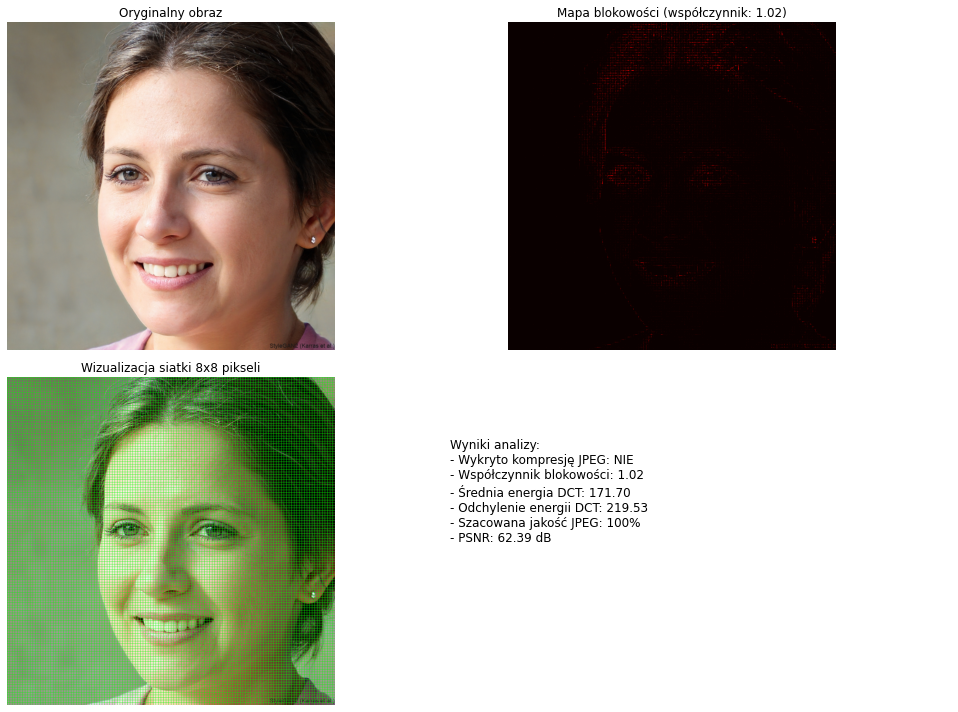

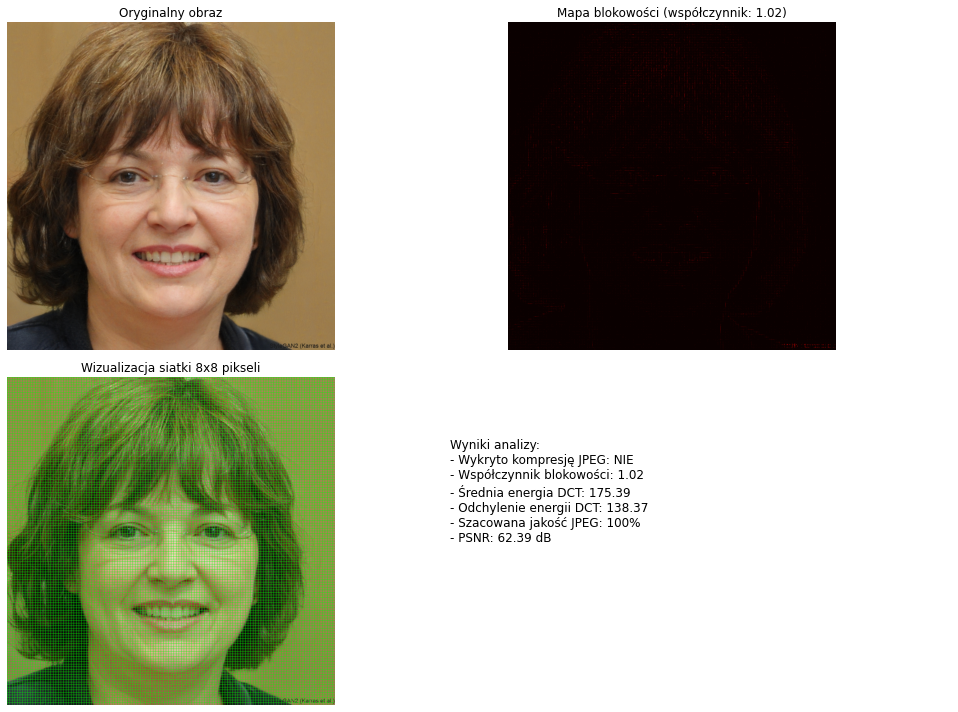

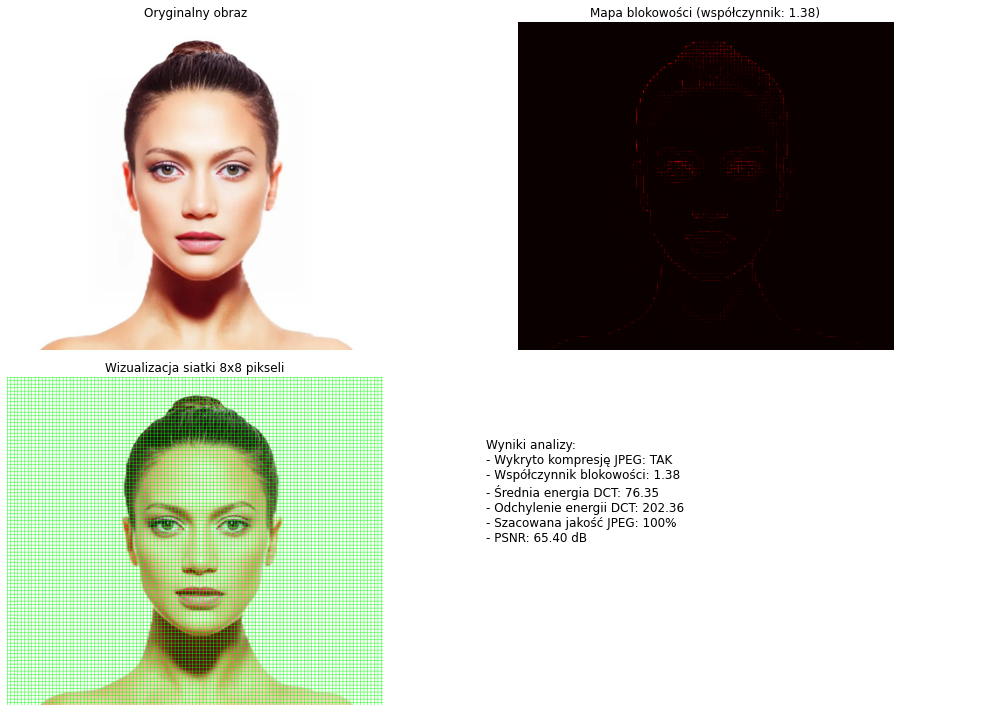

(True, 1.3810383566900895, 100, 65.39747038400974)

In [6]:
# Użycie algorytmu

detect_jpeg_compression("test-images/maly3.png")
detect_jpeg_compression(r"D:\Zbiory danych - praca\ThisPersonDoesntExist\archive (3)\thispersondoesnotexist.10k\0.jpg")
detect_jpeg_compression(r"D:\Zbiory danych - praca\ThisPersonDoesntExist\archive (3)\thispersondoesnotexist.10k\1.jfif")
detect_jpeg_compression("jfif/person_0000.jfif")
detect_jpeg_compression("jfif/person_0001.jfif")
detect_jpeg_compression("test-images/00-swapped-woman.jpg")

# Testowanie wskaźników

In [12]:
# import requests
# import os
# import time
# import random

# from tqdm.notebook import tqdm  # For progress bar in Jupyter notebooks

# # Create directory if it doesn't exist
# os.makedirs("jfif", exist_ok=True)

# # Download 1000 images
# for i in tqdm(range(10000)):
#     try:
#         # Add a random parameter to avoid cache
#         url = f"https://thispersondoesnotexist.com/"
#         response = requests.get(url, headers={
#             'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36'
#         })
        
#         # Check if request was successful
#         if response.status_code == 200:
#             # Save the image
#             with open(f"jfif/person_{i+1001:04d}.jfif", "wb") as f:
#                 f.write(response.content)
            
#             # Add a delay to avoid overwhelming the server
#             time.sleep(random.uniform(0.1, 0.3))
#         else:
#             print(f"Error: Status code {response.status_code} for image {i}")
            
#     except Exception as e:
#         print(f"Error downloading image {i}: {e}")
        
# print("Download complete!")
# last run: 2:48 h

# Powielona kompresja

## Zmiana ppm na png

In [13]:
# from PIL import Image
# import os

# # Zapisz obrazy .ppm z katalogu multiple-compression w formacie png
# multiple_compression_dir = "multiple-compression"

# # Get all PPM files in the directory
# image_files = [f for f in os.listdir(multiple_compression_dir) if f.lower().endswith('.ppm')]

# for fname in image_files:
#     ppm_path = os.path.join(multiple_compression_dir, fname)
#     # Create proper PNG filename by replacing .ppm extension with .png
#     base_name = os.path.splitext(fname)[0]
#     png_path = os.path.join(multiple_compression_dir, base_name + ".png")
    
#     try:
#         # Otwórz plik PPM
#         img = Image.open(ppm_path)
#         # Zapisz jako PNG
#         img.save(png_path)
#         print(f"Zapisano {png_path}")
#     except Exception as e:
#         print(f"Błąd konwersji {ppm_path}: {e}")


## 3-krotna kompresja z różnymi wagami

In [26]:
from PIL import Image
import os

# Kompresuj obrazy z katalogu multiple-compression do JPG z różnymi jakościami kompresji
multiple_compression_dir = "multiple-compression"

# Usuń wszystkie pliki inne niż png i ppm
for f in os.listdir(multiple_compression_dir):
    file_path = os.path.join(multiple_compression_dir, f)
    if os.path.isfile(file_path):
        ext = os.path.splitext(f)[1].lower()
        if ext not in ['.png', '.ppm']:
            try:
                os.remove(file_path)
                print(f"Usunięto {f}")
            except Exception as e:
                print(f"Błąd usuwania {f}: {e}")

# Pobierz wszystkie pliki PNG w katalogu
png_files = [f for f in os.listdir(multiple_compression_dir) if f.lower().endswith('.png')]

# Różne poziomy jakości kompresji JPEG
quality_levels = [10, 30, 50, 70, 85, 95, 100]

for png_file in png_files:
    png_path = os.path.join(multiple_compression_dir, png_file)
    base_name = os.path.splitext(png_file)[0]
    
    try:
        # Otwórz obraz PNG
        img = Image.open(png_path)
        
        # Zapisz z różnymi jakościami kompresji
        for quality in quality_levels:
            jpg_filename = f"{base_name}_q{quality}.jpg"
            jpg_path = os.path.join(multiple_compression_dir, jpg_filename)
            img.save(jpg_path, "JPEG", quality=quality)
            print(f"Zapisano {jpg_filename}")
            
    except Exception as e:
        print(f"Błąd konwersji {png_file}: {e}")

# Wszystkie obrazy w katalogu multiple-compression które są w formacie *.jpg skompresuj kolejny raz do jpeg (standardowo). Oznaczaj je *.jpg.q_.jpg

# Pobierz wszystkie pliki JPG w katalogu
jpg_files = [f for f in os.listdir(multiple_compression_dir) if f.lower().endswith('.jpg')]

for jpg_file in jpg_files:
    jpg_path = os.path.join(multiple_compression_dir, jpg_file)
    
    try:
        # Otwórz obraz JPG
        img = Image.open(jpg_path)
        
        # Zapisz z różnymi jakościami kompresji z nową nazwą
        for quality in quality_levels:
            output_filename = f"{jpg_file}.q{quality}.jpg"
            output_path = os.path.join(multiple_compression_dir, output_filename)
            img.save(output_path, "JPEG", quality=quality)
            print(f"Zapisano {output_filename}")

            sub_image = Image.open(output_path)
            
            for sub_quality in quality_levels:
                sub_output_filename = f"{jpg_file}.q{quality}.q{sub_quality}.jpg"
                sub_output_path = os.path.join(multiple_compression_dir, sub_output_filename)
                sub_image.save(sub_output_path, "JPEG", quality=sub_quality)
                print(f"Zapisano {sub_output_filename}")

    except Exception as e:
        print(f"Błąd kompresji {jpg_file}: {e}")

Usunięto 01 (1)_q10.jpg
Usunięto 01 (1)_q10.jpg.q10.jpg
Usunięto 01 (1)_q10.jpg.q10.q10.jpg
Usunięto 01 (1)_q10.jpg.q10.q100.jpg
Usunięto 01 (1)_q10.jpg.q10.q30.jpg
Usunięto 01 (1)_q10.jpg.q10.q50.jpg
Usunięto 01 (1)_q10.jpg.q10.q70.jpg
Usunięto 01 (1)_q10.jpg.q10.q85.jpg
Usunięto 01 (1)_q10.jpg.q10.q95.jpg
Usunięto 01 (1)_q10.jpg.q100.jpg
Usunięto 01 (1)_q10.jpg.q100.q10.jpg
Usunięto 01 (1)_q10.jpg.q100.q100.jpg
Usunięto 01 (1)_q10.jpg.q100.q30.jpg
Usunięto 01 (1)_q10.jpg.q100.q50.jpg
Usunięto 01 (1)_q10.jpg.q100.q70.jpg
Usunięto 01 (1)_q10.jpg.q100.q85.jpg
Usunięto 01 (1)_q10.jpg.q100.q95.jpg
Usunięto 01 (1)_q10.jpg.q30.jpg
Usunięto 01 (1)_q10.jpg.q30.q10.jpg
Usunięto 01 (1)_q10.jpg.q30.q100.jpg
Usunięto 01 (1)_q10.jpg.q30.q30.jpg
Usunięto 01 (1)_q10.jpg.q30.q50.jpg
Usunięto 01 (1)_q10.jpg.q30.q70.jpg
Usunięto 01 (1)_q10.jpg.q30.q85.jpg
Usunięto 01 (1)_q10.jpg.q30.q95.jpg
Usunięto 01 (1)_q10.jpg.q50.jpg
Usunięto 01 (1)_q10.jpg.q50.q10.jpg
Usunięto 01 (1)_q10.jpg.q50.q100.jpg
Usunięto

## 3-krotna kompresja standardowa

In [41]:
from PIL import Image
import os

# Kompresuj obrazy z katalogu multiple-compression do JPG z różnymi jakościami kompresji
multiple_compression_dir = "multiple-compression"

# Usuń wszystkie pliki inne niż png i ppm
for f in os.listdir(multiple_compression_dir):
    file_path = os.path.join(multiple_compression_dir, f)
    if os.path.isfile(file_path):
        ext = os.path.splitext(f)[1].lower()
        if ext not in ['.png', '.ppm']:
            try:
                os.remove(file_path)
                print(f"Usunięto {f}")
            except Exception as e:
                print(f"Błąd usuwania {f}: {e}")

# Pobierz wszystkie pliki PNG w katalogu
png_files = [f for f in os.listdir(multiple_compression_dir) if f.lower().endswith('.png')]

# Różne poziomy jakości kompresji JPEG
# quality_levels = [10, 30, 50, 70, 85, 95, "keep"]
quality_levels = [10, 30, 50, 65, 75, 85, 95]

for png_file in png_files:
    png_path = os.path.join(multiple_compression_dir, png_file)
    base_name = os.path.splitext(png_file)[0]
    
    try:
        # Otwórz obraz PNG
        img = Image.open(png_path)
        
        # Zapisz z różnymi jakościami kompresji
        for quality in quality_levels:
            jpg_filename = f"{base_name}_q{quality}.jpg"
            jpg_path = os.path.join(multiple_compression_dir, jpg_filename)
            img.save(jpg_path, "JPEG", quality=quality)
            img.save
            print(f"Zapisano {jpg_filename}")
            
    except Exception as e:
        print(f"Błąd konwersji {png_file}: {e}")

# Wszystkie obrazy w katalogu multiple-compression które są w formacie *.jpg skompresuj kolejny raz do jpeg (standardowo). Oznaczaj je *.jpg.q_.jpg

# Pobierz wszystkie pliki JPG w katalogu
jpg_files = [f for f in os.listdir(multiple_compression_dir) if f.lower().endswith('.jpg')]

for jpg_file in jpg_files:
    jpg_path = os.path.join(multiple_compression_dir, jpg_file)
    
    try:
        # Otwórz obraz JPG
        img = Image.open(jpg_path)
        
        # Zapisz z różnymi jakościami kompresji z nową nazwą
        for quality in quality_levels:
            output_filename = f"{jpg_file}.q{quality}.jpg"
            output_path = os.path.join(multiple_compression_dir, output_filename)
            img.save(output_path, "JPEG", quality=quality)
            print(f"Zapisano {output_filename}")

            sub_image = Image.open(output_path)
            
            for sub_quality in quality_levels:
                sub_output_filename = f"{jpg_file}.q{quality}.q{sub_quality}.jpg"
                sub_output_path = os.path.join(multiple_compression_dir, sub_output_filename)
                sub_image.save(sub_output_path, "JPEG", quality=sub_quality)
                print(f"Zapisano {sub_output_filename}")

    except Exception as e:
        print(f"Błąd kompresji {jpg_file}: {e}")

Usunięto 01 (1)_q50.jpg
Usunięto 01 (1)_q50.jpg.q50.jpg
Usunięto 01 (1)_q50.jpg.q50.q50.jpg
Usunięto 01 (2)_q50.jpg
Usunięto 01 (2)_q50.jpg.q50.jpg
Usunięto 01 (2)_q50.jpg.q50.q50.jpg
Usunięto 01 (3)_q50.jpg
Usunięto 01 (3)_q50.jpg.q50.jpg
Usunięto 01 (3)_q50.jpg.q50.q50.jpg
Usunięto 01 (4)_q50.jpg
Usunięto 01 (4)_q50.jpg.q50.jpg
Usunięto 01 (4)_q50.jpg.q50.q50.jpg
Usunięto 01 (5)_q50.jpg
Usunięto 01 (5)_q50.jpg.q50.jpg
Usunięto 01 (5)_q50.jpg.q50.q50.jpg
Usunięto 01 (6)_q50.jpg
Usunięto 01 (6)_q50.jpg.q50.jpg
Usunięto 01 (6)_q50.jpg.q50.q50.jpg
Zapisano 01 (1)_q10.jpg
Zapisano 01 (1)_q30.jpg
Zapisano 01 (1)_q50.jpg
Zapisano 01 (1)_q65.jpg
Zapisano 01 (1)_q75.jpg
Zapisano 01 (1)_q85.jpg
Zapisano 01 (1)_q95.jpg
Zapisano 01 (2)_q10.jpg
Zapisano 01 (2)_q30.jpg
Zapisano 01 (2)_q50.jpg
Zapisano 01 (2)_q65.jpg
Zapisano 01 (2)_q75.jpg
Zapisano 01 (2)_q85.jpg
Zapisano 01 (2)_q95.jpg
Zapisano 01 (3)_q10.jpg
Zapisano 01 (3)_q30.jpg
Zapisano 01 (3)_q50.jpg
Zapisano 01 (3)_q65.jpg
Zapisano 01 (3)_

## Wyliczenie wskźników dla obrazów

In [ ]:
import os
# Get all files in the multiple-compression directory
image_files = [os.path.join("multiple-compression", f) for f in os.listdir("multiple-compression") if os.path.isfile(os.path.join("multiple-compression", f)) and f.lower().endswith(('.jpg', '.jpeg', '.png', '.ppm'))]

# Initialize lists to store metrics
results = []

# Process each image file
for image_path in image_files:
    print(f"\nAnalyzing: {image_path}")
    try:
        img = cv2.imread(image_path)
        if img is None:
            print(f"Could not load image: {image_path}")
            continue
        
        # Calculate blockiness metrics
        blockiness_ratios = detect_jpeg_blockiness(img)  # Tablica 8 wartości
        blockiness_ratio_max = np.max(blockiness_ratios)
        blockiness_ratio_mean = np.mean(blockiness_ratios)
        # blockiness_ext, block_diff_std, non_block_diff_std = detect_jpeg_blockiness_extended(img)
        
        # Calculate DCT energy metrics
        energy_mean, energy_std = analyze_dct_spectrum(img)
        
        # Estimate JPEG quality
        estimated_quality, psnr_value = estimate_jpeg_quality(img)
        
        # Store results
        result_dict = {
            'filename': os.path.basename(image_path),
            'blockiness_ratio_max': blockiness_ratio_max,
            'blockiness_ratio_mean': blockiness_ratio_mean,
            # 'blockiness_extended': blockiness_ext,
            # 'block_diff_std': block_diff_std,
            # 'non_block_diff_std': non_block_diff_std,
            'energy_mean': energy_mean,
            'energy_std': energy_std,
            'estimated_quality': estimated_quality,
            'psnr': psnr_value
        }
        
        # Dodaj każdy współczynnik blokowości osobno
        for i, ratio in enumerate(blockiness_ratios):
            result_dict[f'blockiness_ratio_{i}'] = ratio
        
        results.append(result_dict)
        
        # print(f"  Blockiness ratio: {blockiness_ratio:.3f}")
        # print(f"  Estimated quality: {estimated_quality}%")
        # print(f"  PSNR: {psnr_value:.2f} dB")
        
    except Exception as e:
        print(f"Error processing {image_path}: {e}")

print(f"\nProcessed {len(results)} images successfully")


Analyzing: multiple-compression\01 (1).png

Analyzing: multiple-compression\01 (1).ppm

Analyzing: multiple-compression\01 (1)_q10.jpg

Analyzing: multiple-compression\01 (1)_q10.jpg.q10.jpg

Analyzing: multiple-compression\01 (1)_q10.jpg.q10.q10.jpg

Analyzing: multiple-compression\01 (1)_q10.jpg.q10.q30.jpg

Analyzing: multiple-compression\01 (1)_q10.jpg.q10.q50.jpg

Analyzing: multiple-compression\01 (1)_q10.jpg.q10.q65.jpg

Analyzing: multiple-compression\01 (1)_q10.jpg.q10.q75.jpg

Analyzing: multiple-compression\01 (1)_q10.jpg.q10.q85.jpg

Analyzing: multiple-compression\01 (1)_q10.jpg.q10.q95.jpg

Analyzing: multiple-compression\01 (1)_q10.jpg.q30.jpg

Analyzing: multiple-compression\01 (1)_q10.jpg.q30.q10.jpg

Analyzing: multiple-compression\01 (1)_q10.jpg.q30.q30.jpg

Analyzing: multiple-compression\01 (1)_q10.jpg.q30.q50.jpg

Analyzing: multiple-compression\01 (1)_q10.jpg.q30.q65.jpg

Analyzing: multiple-compression\01 (1)_q10.jpg.q30.q75.jpg

Analyzing: multiple-compression

## Prezentacja statystyk

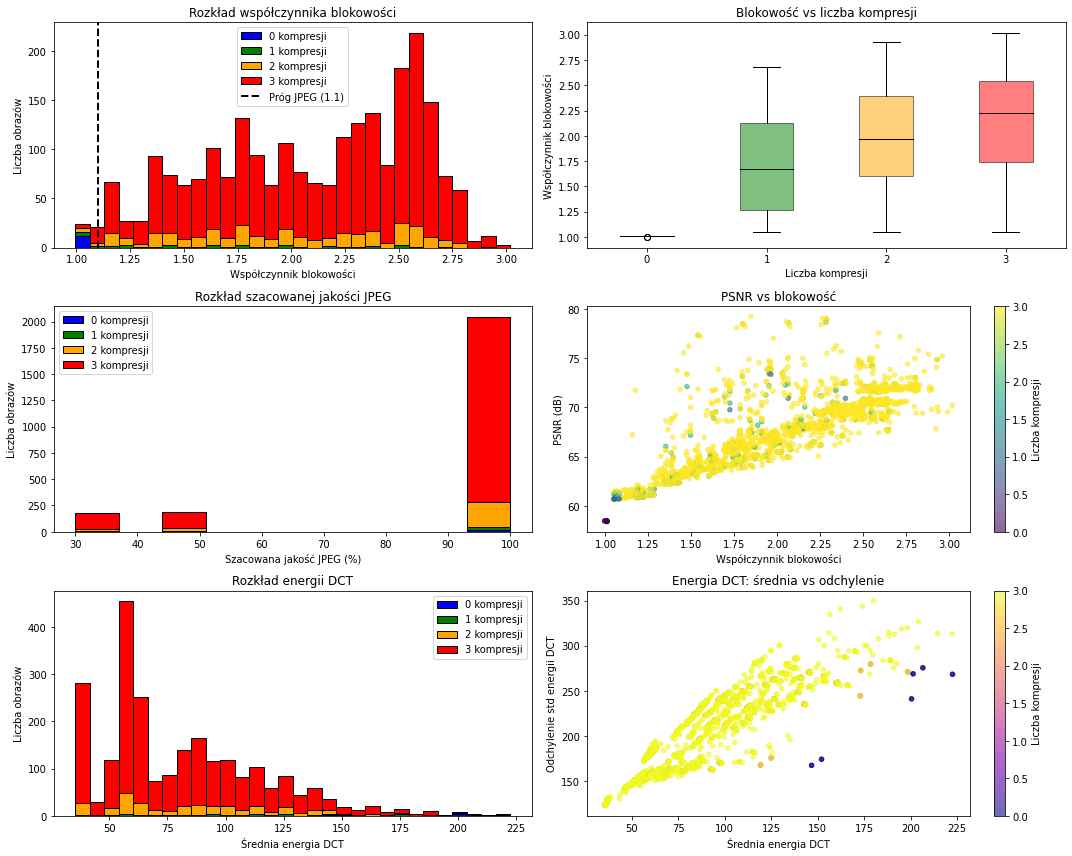


=== Statystyki opisowe ===
       blockiness_ratio  estimated_quality         psnr  energy_mean  \
count       2406.000000        2406.000000  2406.000000  2406.000000   
mean           2.082177          90.989194    68.129244    81.266327   
std            0.478698          21.697655     3.727273    34.626476   
min            0.994612          30.000000    58.411209    35.382763   
25%            1.711307         100.000000    65.135202    58.365707   
50%            2.152295         100.000000    68.959619    71.599583   
75%            2.520798         100.000000    70.613097   101.325727   
max            3.020105         100.000000    79.219901   222.438919   

        energy_std  
count  2406.000000  
mean    192.349060  
std      45.225521  
min     122.674019  
25%     156.633804  
50%     181.305305  
75%     229.270344  
max     349.760162  

=== Średnie wartości według liczby kompresji ===
                   blockiness_ratio  estimated_quality       psnr
compression_count 

In [ ]:
# Tworzenie wykresów i histogramów na podstawie wyników analizy
import pandas as pd
import numpy as np

# Konwertuj wyniki do DataFrame dla łatwiejszej analizy
results_df = pd.DataFrame(results)

# Dodaj kolumnę z informacją o liczbie kompresji (na podstawie nazwy pliku)
def get_compression_count(filename):
    # Zlicz wystąpienia '.q' w nazwie pliku
    q_count = filename.count('.q')
    
    if filename.endswith('.png') or filename.endswith('.ppm'):
        return 0  # Brak kompresji JPEG
    elif q_count == 0:
        return 1  # Pojedyncza kompresja (np. _q10.jpg)
    else:
        return q_count + 1  # Liczba '.q' + 1 = całkowita liczba kompresji

results_df['compression_count'] = results_df['filename'].apply(get_compression_count)

# Stwórz figurę z wieloma wykresami
fig, axes = plt.subplots(3, 2, figsize=(15, 12))

# Kolory dla różnych poziomów kompresji
colors = ['blue', 'green', 'orange', 'red']
compression_levels = sorted(results_df['compression_count'].unique())

# 1. Histogram współczynnika blokowości (max) z podziałem na liczbę kompresji (stacked)
data_blockiness = [results_df[results_df['compression_count'] == comp]['blockiness_ratio_max'].values 
                   for comp in compression_levels]
axes[0, 0].hist(data_blockiness, bins=30, label=[f'{comp} kompresji' for comp in compression_levels], 
                color=colors[:len(compression_levels)], edgecolor='black', stacked=True)
axes[0, 0].set_xlabel('Współczynnik blokowości (max)')
axes[0, 0].set_ylabel('Liczba obrazów')
axes[0, 0].set_title('Rozkład współczynnika blokowości (max)')
axes[0, 0].axvline(1.1, color='black', linestyle='--', linewidth=2, label='Próg JPEG (1.1)')
axes[0, 0].legend()

# 2. Boxplot współczynnika blokowości według liczby kompresji
compression_groups = results_df.groupby('compression_count')['blockiness_ratio_max'].apply(list)
bp = axes[0, 1].boxplot(compression_groups.values, labels=compression_groups.index, patch_artist=True)
for patch, color in zip(bp['boxes'], colors[:len(compression_groups)]):
    patch.set_facecolor(color)
    patch.set_alpha(0.5)
# Zmień kolor linii mediany na czarny
for median in bp['medians']:
    median.set_color('black')
    median.set_linewidth(1)
axes[0, 1].set_xlabel('Liczba kompresji')
axes[0, 1].set_ylabel('Współczynnik blokowości (max)')
axes[0, 1].set_title('Blokowość (max) vs liczba kompresji')

# 3. Histogram szacowanej jakości JPEG z podziałem na liczbę kompresji (stacked)
data_quality = [results_df[results_df['compression_count'] == comp]['estimated_quality'].values 
                for comp in compression_levels]
axes[1, 0].hist(data_quality, bins=10, label=[f'{comp} kompresji' for comp in compression_levels],
                color=colors[:len(compression_levels)], edgecolor='black', stacked=True)
axes[1, 0].set_xlabel('Szacowana jakość JPEG (%)')
axes[1, 0].set_ylabel('Liczba obrazów')
axes[1, 0].set_title('Rozkład szacowanej jakości JPEG')
axes[1, 0].legend()

# 4. Scatter plot: PSNR vs współczynnik blokowości
scatter = axes[1, 1].scatter(results_df['blockiness_ratio_max'], results_df['psnr'], 
                             c=results_df['compression_count'], cmap='viridis', alpha=0.6, s=20)
axes[1, 1].set_xlabel('Współczynnik blokowości (max)')
axes[1, 1].set_ylabel('PSNR (dB)')
axes[1, 1].set_title('PSNR vs blokowość (max)')
plt.colorbar(scatter, ax=axes[1, 1], label='Liczba kompresji')

# 5. Histogram energii DCT z podziałem na liczbę kompresji (stacked)
data_energy = [results_df[results_df['compression_count'] == comp]['energy_mean'].values 
               for comp in compression_levels]
axes[2, 0].hist(data_energy, bins=30, label=[f'{comp} kompresji' for comp in compression_levels],
                color=colors[:len(compression_levels)], edgecolor='black', stacked=True)
axes[2, 0].set_xlabel('Średnia energia DCT')
axes[2, 0].set_ylabel('Liczba obrazów')
axes[2, 0].set_title('Rozkład energii DCT')
axes[2, 0].legend()

# 6. Scatter plot: Energia DCT vs odchylenie
scatter2 = axes[2, 1].scatter(results_df['energy_mean'], results_df['energy_std'], 
                              c=results_df['compression_count'], cmap='plasma', alpha=0.6, s=20)
axes[2, 1].set_xlabel('Średnia energia DCT')
axes[2, 1].set_ylabel('Odchylenie std energii DCT')
axes[2, 1].set_title('Energia DCT: średnia vs odchylenie')
plt.colorbar(scatter2, ax=axes[2, 1], label='Liczba kompresji')

plt.tight_layout()
plt.show()

# Statystyki opisowe
print("\n=== Statystyki opisowe ===")
blockiness_cols = [f'blockiness_ratio_{i}' for i in range(8)] + ['blockiness_ratio_max', 'blockiness_ratio_mean']
print(results_df[blockiness_cols + ['estimated_quality', 'psnr', 'energy_mean', 'energy_std']].describe())

# Statystyki według liczby kompresji
print("\n=== Średnie wartości według liczby kompresji ===")
print(results_df.groupby('compression_count')[['blockiness_ratio_max', 'blockiness_ratio_mean', 'estimated_quality', 'psnr']].mean())

# Wyświetl liczbę obrazów dla każdej liczby kompresji
print("\n=== Liczba obrazów według liczby kompresji ===")
print(results_df['compression_count'].value_counts().sort_index())

## Analiza wszystkich 8 współczynników blokowości

In [ ]:
# Analiza wszystkich 8 współczynników blokowości dla różnych liczb kompresji

# Przygotuj dane dla wszystkich 8 współczynników
blockiness_cols = [f'blockiness_ratio_{i}' for i in range(8)]

# Utwórz figurę z wykresami
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Wykres liniowy: średnie wartości dla każdego współczynnika według liczby kompresji
ax = axes[0, 0]
for comp_level in compression_levels:
    comp_data = results_df[results_df['compression_count'] == comp_level]
    means = [comp_data[col].mean() for col in blockiness_cols]
    ax.plot(range(8), means, marker='o', label=f'{comp_level} kompresji', linewidth=2)

ax.set_xlabel('Pozycja granicy w bloku 8x8')
ax.set_ylabel('Średni współczynnik blokowości')
ax.set_title('Współczynniki blokowości dla różnych granic bloków')
ax.legend()
ax.grid(True, alpha=0.3)
ax.set_xticks(range(8))
ax.axhline(1.1, color='red', linestyle='--', alpha=0.5, label='Próg JPEG (1.1)')

# 2. Boxplot: rozkład dla współczynnika 7 (granica główna) vs 0-6
ax = axes[0, 1]
data_to_plot = [results_df[col].values for col in blockiness_cols]
bp = ax.boxplot(data_to_plot, labels=range(8), patch_artist=True)
for i, patch in enumerate(bp['boxes']):
    if i == 7:
        patch.set_facecolor('red')
        patch.set_alpha(0.7)
    else:
        patch.set_facecolor('lightblue')
        patch.set_alpha(0.5)
for median in bp['medians']:
    median.set_color('black')
    median.set_linewidth(2)
ax.set_xlabel('Pozycja granicy w bloku 8x8')
ax.set_ylabel('Współczynnik blokowości')
ax.set_title('Rozkład współczynników blokowości (czerwony = granica 7-8)')
ax.axhline(1.1, color='red', linestyle='--', alpha=0.5)
ax.grid(True, alpha=0.3, axis='y')

# 3. Heatmapa: średnie wartości dla każdej liczby kompresji i każdej granicy
ax = axes[1, 0]
heatmap_data = []
for comp_level in compression_levels:
    comp_data = results_df[results_df['compression_count'] == comp_level]
    means = [comp_data[col].mean() for col in blockiness_cols]
    heatmap_data.append(means)

im = ax.imshow(heatmap_data, cmap='YlOrRd', aspect='auto')
ax.set_xlabel('Pozycja granicy w bloku 8x8')
ax.set_ylabel('Liczba kompresji')
ax.set_title('Mapa cieplna: średnie współczynniki blokowości')
ax.set_xticks(range(8))
ax.set_yticks(range(len(compression_levels)))
ax.set_yticklabels(compression_levels)

# Dodaj wartości na heatmapie
for i in range(len(compression_levels)):
    for j in range(8):
        text = ax.text(j, i, f'{heatmap_data[i][j]:.2f}',
                      ha="center", va="center", color="black", fontsize=9)

plt.colorbar(im, ax=ax, label='Średni współczynnik blokowości')

# 4. Histogram: stosunek współczynnika 7 do średniej z 0-6
ax = axes[1, 1]
results_df['ratio_7_to_others'] = results_df['blockiness_ratio_7'] / results_df[[f'blockiness_ratio_{i}' for i in range(7)]].mean(axis=1)

data_ratio = [results_df[results_df['compression_count'] == comp]['ratio_7_to_others'].values 
              for comp in compression_levels]
ax.hist(data_ratio, bins=30, label=[f'{comp} kompresji' for comp in compression_levels],
        color=colors[:len(compression_levels)], edgecolor='black', stacked=True)
ax.set_xlabel('Stosunek współczynnika [7] do średniej [0-6]')
ax.set_ylabel('Liczba obrazów')
ax.set_title('Stosunek głównej granicy do pozostałych')
ax.axvline(1.0, color='black', linestyle='--', linewidth=2, label='Równowaga (1.0)')
ax.legend()

plt.tight_layout()
plt.show()

# Wyświetl statystyki
print("\n=== Średnie wartości wszystkich współczynników blokowości ===")
for i in range(8):
    col = f'blockiness_ratio_{i}'
    print(f"\nWspółczynnik [{i}] (granica {i}-{i+1}):")
    print(results_df.groupby('compression_count')[col].mean())

print("\n=== Stosunek współczynnika [7] do średniej [0-6] według liczby kompresji ===")
print(results_df.groupby('compression_count')['ratio_7_to_others'].describe())